# GridMind: sampled XGBoost forecasting baseline

Train three separate one-hour predictors for demand, solar and wind; derive net load.
**17,544 continuous sampled hours from 2023–2024**, with 168 warmup hours and chronological
**13,900 / 1,738 / 1,738** train/validation/test examples. Raw data stays unchanged.

This is an adapted PoC, not a reproduction of the paper's neural experiments.
The held-out periods cover about 72 days each and cannot establish year-round performance.


In [1]:
# Colab only: clone the repository on first use and install dependencies.
# Local VS Code: select your prepared Python environment instead.
import sys
import subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not Path('/content/GridMind').exists():
        subprocess.run(['git', 'clone', 'https://github.com/karimarefx/GridMind.git', '/content/GridMind'], check=True)
    ROOT = Path('/content/GridMind')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT/'requirements-forecasting.txt')], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gridmind/forecasting.py').exists())
sys.path.insert(0, str(ROOT/'src'))
print('Repository:', ROOT)


Repository: C:\Users\Galal\Desktop\GP_POC\GridMind


## 1. Inspect the selected sample and freeze the split

Only the fixed sample is retained in memory. Validation rejects missing/nonfinite values,
duplicates, gaps, inconsistent net load and a proxy inconsistent with the documented local-hour formula.
UTC/hour-ending interpretation follows the repository; independent workbook provenance remains unresolved.


In [2]:
import pandas as pd
import numpy as np
from gridmind.forecasting import load_sample, partition, run, predict_next, HISTORY

sample = load_sample(ROOT/'data/raw/ercot_2021_2024_hourly.csv')
split = partition(sample.index[HISTORY:])
display(sample.head())
display(sample.describe())
display(pd.DataFrame([{'split': s, 'examples': int((split == s).sum()),
                      'first_target_utc': split[split == s].index.min(),
                      'last_target_utc': split[split == s].index.max()} for s in split.unique()]))


,wind_generation,wind_installed,total_load,solar_generation,solar_installed,net_load,clear_sky_proxy
time,,,,,,,
2023-01-01 06:00:00+00:00,22017.020694,36858,36650.284599,0.449177,14249,14632.814727,0.0
2023-01-01 07:00:00+00:00,21753.284477,36858,35829.306163,0.449746,14249,14075.571940,0.0
2023-01-01 08:00:00+00:00,21570.395694,36858,35245.390234,0.454733,14249,13674.539807,0.0
2023-01-01 09:00:00+00:00,21036.504013,36858,34599.761810,0.443528,14249,13562.814269,0.0
2023-01-01 10:00:00+00:00,20595.481515,36858,34227.151061,0.458567,14249,13631.210980,0.0


,wind_generation,wind_installed,total_load,solar_generation,solar_installed,net_load,clear_sky_proxy
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.00000,17544.000000,1.754400e+04
mean,12523.291363,38438.445508,51943.917713,4538.154812,20901.70269,34882.471538,3.164898e-01
std,6629.191623,809.617768,11168.424839,5868.874922,4640.39375,11817.645649,3.870953e-01
min,37.929258,36858.000000,33681.540790,0.000010,14249.00000,11126.677257,0.000000e+00
25%,6804.222226,37676.000000,43862.623581,0.329000,16526.00000,25653.891229,0.000000e+00
50%,12128.963137,38631.000000,48787.826209,290.820260,21173.00000,34111.960573,6.123234e-17
75%,18204.258039,39380.000000,57851.427036,9177.474748,25153.00000,42512.028311,7.071068e-01
max,27666.564470,39397.000000,85544.435964,21588.538561,28793.00000,70435.122052,1.000000e+00


,split,examples,first_target_utc,last_target_utc
0,train,13900,2023-01-08 06:00:00+00:00,2024-08-09 09:00:00+00:00
1,validation,1738,2024-08-09 10:00:00+00:00,2024-10-20 19:00:00+00:00
2,test,1738,2024-10-20 20:00:00+00:00,2025-01-01 05:00:00+00:00


## 2. Fit the fixed baseline configuration

Each model uses only historical measurements. Demand/wind use 24-hour flattened windows;
solar uses 15 historical channels and a daily capacity-factor residual target, requiring 72 raw hours.
No weather, random row splitting or future capacities. Last-known capacity is used at inference.

CPU histogram trees; depth 4; learning rate 0.05; at most 500 trees; 30-round validation early stopping.
Test targets never control fitting. Rerun only for reproducibility, not to tune against test results.
This cell exports models and reports and checks model reload plus batch/request equivalence.


In [3]:
metrics = run(ROOT)
display(metrics.query("group == 'all'").round(3))


demand {'best_iteration': 499, 'training_seconds': 33.03390669997316, 'features': 1728, 'model_bytes': 1034311, 'clipping_fraction': 0.0}


solar {'best_iteration': 386, 'training_seconds': 11.180238300003111, 'features': 360, 'model_bytes': 867440, 'clipping_fraction': 0.20839088397790057}


wind {'best_iteration': 498, 'training_seconds': 26.810263699968345, 'features': 1752, 'model_bytes': 1031545, 'clipping_fraction': 0.0}


,target,split,group,method,mae_mw,rmse_mw,r2,n,mae_skill_vs_persistence
0,demand,validation,all,xgboost,553.063,718.615,0.996,1738,0.731
1,demand,validation,all,persistence,2055.331,2381.692,0.953,1738,0.000
2,demand,validation,all,daily,1763.389,2564.612,0.946,1738,0.142
3,demand,validation,all,weekly,4649.219,5867.677,0.716,1738,-1.262
20,demand,test,all,xgboost,485.982,642.099,0.986,1738,0.561
21,demand,test,all,persistence,1106.503,1365.965,0.936,1738,0.000
22,demand,test,all,daily,2091.491,2812.410,0.727,1738,-0.890
23,demand,test,all,weekly,3554.599,4635.374,0.258,1738,-2.212
36,solar,validation,all,xgboost,308.083,578.196,0.995,1738,0.802
37,solar,validation,all,persistence,1555.796,3062.894,0.862,1738,0.000


## 3. Compare held-out errors

MAE and RMSE are in MW. R² is not accuracy. Positive MAE skill means lower error than
last-observation persistence. Inspect component scores independently: net-load errors can cancel.
Solar daily capacity-factor persistence is an additional baseline.


In [4]:
test = metrics.query("split == 'test' and group == 'all'")
display(test.pivot(index='target', columns='method', values='mae_mw').round(2))
display(metrics.query("split == 'test' and method == 'xgboost'").round(3))


method,daily,daily_cf,persistence,weekly,xgboost
target,,,,,
demand,2091.49,NaN,1106.50,3554.60,485.98
net_load,6475.22,NaN,1868.06,8620.61,837.76
solar,1274.41,1274.79,1234.13,1905.27,359.34
wind,6877.69,NaN,884.66,8541.42,645.30


,target,split,group,method,mae_mw,rmse_mw,r2,n,mae_skill_vs_persistence
20,demand,test,all,xgboost,485.982,642.099,0.986,1738,0.561
24,demand,test,ramp,xgboost,2098.878,2160.082,0.800,7,0.486
28,demand,test,winter,xgboost,457.749,614.484,0.973,744,0.507
32,demand,test,autumn,xgboost,507.114,662.016,0.989,994,0.591
66,solar,test,all,xgboost,359.343,720.614,0.988,1738,0.709
71,solar,test,peak,xgboost,721.130,1012.939,0.563,235,0.472
76,solar,test,ramp,xgboost,1050.472,1433.563,0.936,166,0.859
81,solar,test,winter,xgboost,352.880,706.569,0.985,744,0.691
86,solar,test,autumn,xgboost,364.181,730.950,0.989,994,0.720
91,solar,test,daylight,xgboost,731.458,1045.781,0.972,795,0.621


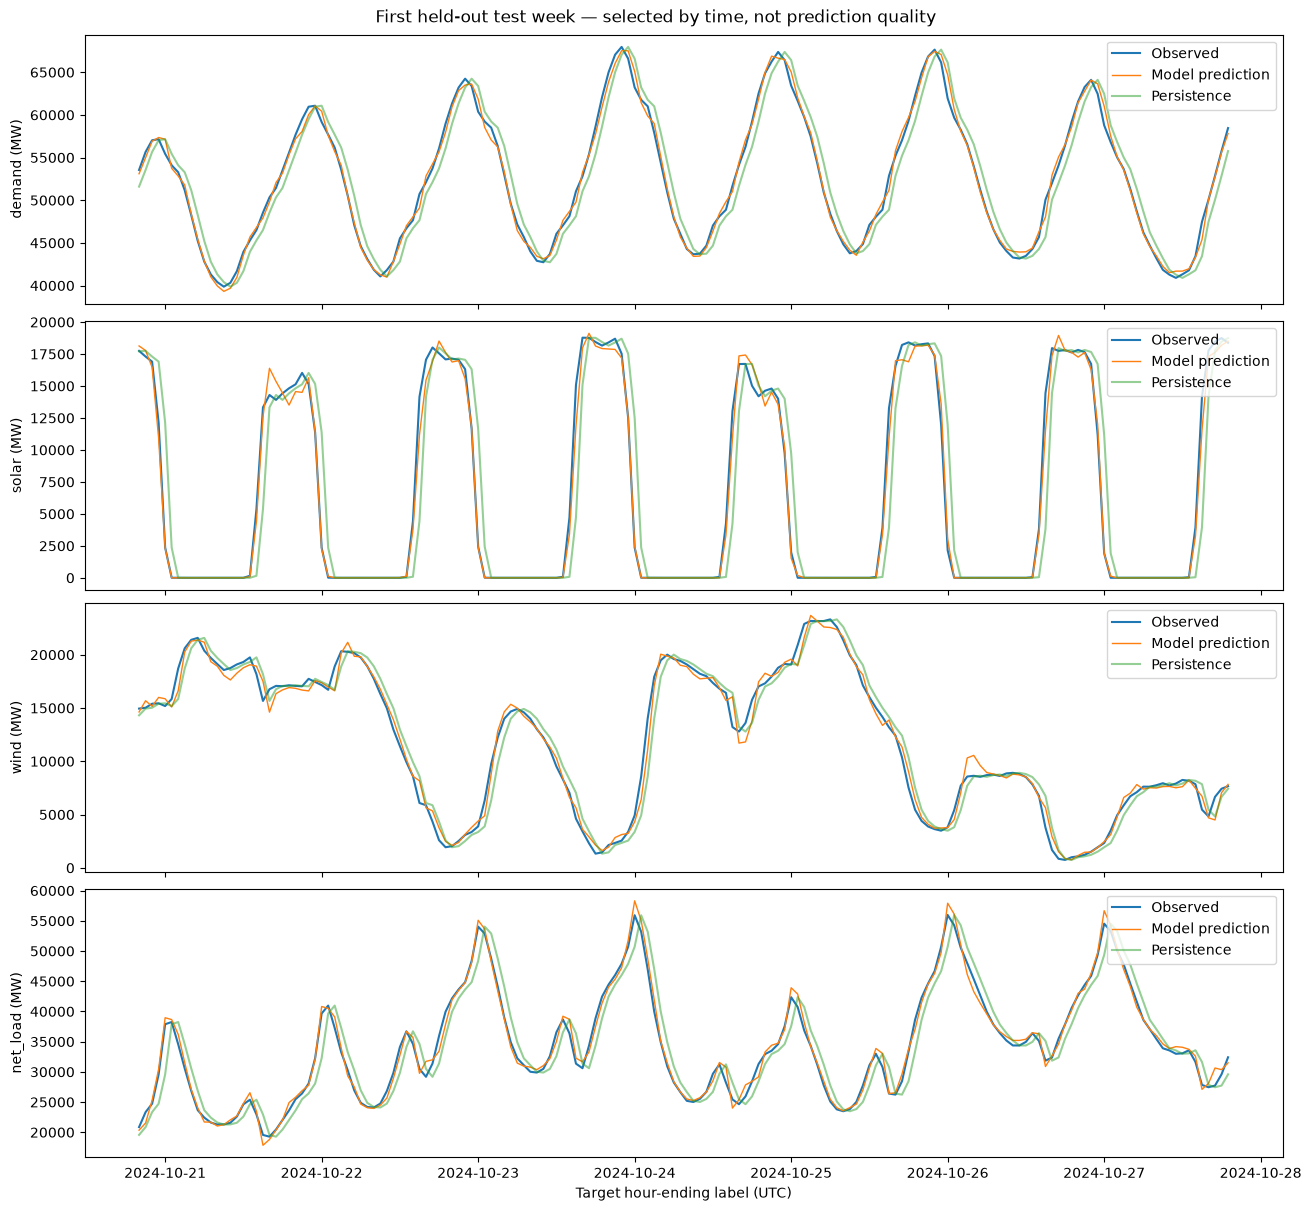

In [5]:
import matplotlib.pyplot as plt

predictions = pd.read_csv(ROOT/'reports/forecasting/predictions.csv', index_col=0, parse_dates=True)
week = predictions.loc[predictions['split'] == 'test'].iloc[:168]
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True, layout='constrained')
for ax, kind in zip(axes, ['demand', 'solar', 'wind', 'net_load']):
    ax.plot(week.index, week[f'{kind}_actual'], label='Observed', linewidth=1.5)
    ax.plot(week.index, week[f'{kind}_xgboost'], label='Model prediction', linewidth=1)
    ax.plot(week.index, week[f'{kind}_persistence'], label='Persistence', alpha=.5)
    ax.set_ylabel(f'{kind} (MW)')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Target hour-ending label (UTC)')
fig.suptitle('First held-out test week — selected by time, not prediction quality')
fig.savefig(ROOT/'reports/forecasting/test_week.png', dpi=140)
plt.show()


## 4. Forecast from history with the exported bundle

This is a replay of the first held-out hour. Only completed observations before its target label are passed.
The interface returns issue/target UTC timestamps, MW predictions and calculated net load.
Insufficient, missing or incompatible history raises a clear error rather than inventing values.


In [6]:
target = split[split == 'test'].index[0]
history = sample.loc[sample.index < target].iloc[-168:]
forecast = predict_next(history, ROOT/'artifacts/forecasting')
display(pd.Series(forecast))


issued_at_utc          2024-10-20T19:00:00+00:00
target_time_utc        2024-10-20T20:00:00+00:00
horizon_hours                                  1
region_id                                  ERCOT
provenance                      Model prediction
model_version                  xgboost-sample-v1
data_quality_status                     complete
demand_mw                           53104.070312
solar_mw                            18131.370406
wind_mw                             14629.024414
net_load_mw                         20343.675493
dtype: object

## 5. Save results

The exported manifest records feature order, source checksum, sample boundaries, split counts,
versions, model sizes, clipping rates, runtimes and limitations. Model binaries are versioned with this PoC.
Colab requires the notebook and new source files to be pushed/uploaded before its clone step can use them.
Downloading this archive preserves artifacts when a Colab session ends.


In [7]:
import json
manifest = json.loads((ROOT/'artifacts/forecasting/manifest.json').read_text())
display(pd.DataFrame(manifest['models']).T)
print('Total measured seconds:', round(manifest['total_seconds'], 2))
print('Limitations:')
print('\n'.join('- '+s for s in manifest['limitations']))
if IN_COLAB:
    import shutil
    from google.colab import files
    export = ROOT/'forecasting_export'
    export.mkdir(exist_ok=True)
    for folder in ['artifacts/forecasting', 'reports/forecasting', 'src/gridmind']:
        shutil.copytree(ROOT/folder, export/folder, dirs_exist_ok=True)
    archive = shutil.make_archive(str(ROOT/'forecasting_export'), 'zip', export)
    files.download(archive)


,best_iteration,training_seconds,features,model_bytes,clipping_fraction
demand,499.0,33.033907,1728.0,1034311.0,0.000000
solar,386.0,11.180238,360.0,867440.0,0.208391
wind,498.0,26.810264,1752.0,1031545.0,0.000000


Total measured seconds: 76.48
Limitations:
- UTC hour-ending semantics follow supplied documentation, not an independent workbook audit.
- Assumes completed source hour is available immediately at issue time.
- Last-observed installed capacity used for clipping/reconstruction; historical publication timing unverified.
- Uniform solar weights; no weather; no neural-model reproduction.
- Held-out windows do not cover all seasons; no full-year generalization claim.
